# Workers' Compensation Claims Valuation & Risk Triage
**Course Project:** Data Mining & Machine Learning (DMML)  
**Authors:** Marius Occhiminuti · Gaëtan Amiens  
**Dataset:** Workers' Compensation Claims (100,000 Records)


## 1. Imports & Global Settings

In [1]:
import os
import re
import math
import warnings
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import scipy.sparse as sp

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.cluster import KMeans
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import RidgeCV
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    silhouette_score,
    confusion_matrix,
)
from sklearn.model_selection import KFold, train_test_split, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler, StandardScaler, FunctionTransformer, Normalizer

from lightgbm import LGBMRegressor, LGBMClassifier

import torch
from transformers import AutoTokenizer, AutoModel

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42
SEED = 42
TEST_SIZE = 0.20
N_FOLDS = 5
TOP_FRAC = 0.10
N_BOOT = 1000
N_JOBS = os.cpu_count() or 2

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
HAVE_CUDA = torch.cuda.is_available()

print("All libraries imported successfully!")
print(f"PyTorch active device: {device}")

All libraries imported successfully!
PyTorch active device: cuda


## 2. Load Dataset & Feature Engineering
Dataset is loaded once into memory to speed up iteration.


In [2]:
def resolve_data_path(csv_filename: str = "workers_comp.csv") -> str:
    script_dir = Path.cwd()
    candidates = [
        Path(csv_filename),
        script_dir / csv_filename,
        script_dir.parent / csv_filename,
        script_dir / "src" / csv_filename
    ]
    for p in candidates:
        if p.exists():
            return str(p)
    checked = "\n".join([f" - {p.resolve()}" for p in candidates])
    raise FileNotFoundError(f"Dataset '{csv_filename}' not found. Checked:\n{checked}")

data_path = resolve_data_path("workers_comp.csv")
print(f"Loading dataset from: {data_path}")
raw = pd.read_csv(data_path)
df = raw.copy()

# Datetime Parsing & Feature Engineering
df["DateTimeOfAccident"] = pd.to_datetime(df["DateTimeOfAccident"], utc=True).dt.tz_localize(None)
df["DateReported"] = pd.to_datetime(df["DateReported"], utc=True).dt.tz_localize(None)

delay = (df["DateReported"] - df["DateTimeOfAccident"]).dt.total_seconds() / 86400
df["ReportDelayDays"] = delay.clip(lower=0)

df["AccidentYear"] = df["DateTimeOfAccident"].dt.year
df["AccidentMonth"] = df["DateTimeOfAccident"].dt.month
df["AccidentHour"] = df["DateTimeOfAccident"].dt.hour
df["AccidentWeekday"] = df["DateTimeOfAccident"].dt.weekday

if "ClaimDescription" in df.columns:
    df["ClaimDescription"] = df["ClaimDescription"].fillna("").astype(str)

TARGET = "UltimateIncurredClaimCost"
LOG_NUM = ["WeeklyPay", "ReportDelayDays", "InitialCaseEstimate"]
LIN_NUM = ["Age", "HoursWorkedPerWeek", "DaysWorkedPerWeek", "DependentChildren", "DependentsOther"]
DATE_NUM = ["AccidentYear", "AccidentMonth", "AccidentHour", "AccidentWeekday"]
CAT = ["Gender", "MaritalStatus", "PartTimeFullTime"]
TEXT = "ClaimDescription"
TAB_COLS = LOG_NUM + LIN_NUM + DATE_NUM + CAT

print(f"Dataset loaded: {df.shape[0]} rows, {df.shape[1]} columns.")
df.head(3)

Loading dataset from: c:\Users\gaeta\Desktop\ISLANDE\RU\COURS\ML\Project\workers_comp.csv
Dataset loaded: 100000 rows, 19 columns.


,DateTimeOfAccident,DateReported,Age,Gender,MaritalStatus,DependentChildren,DependentsOther,WeeklyPay,PartTimeFullTime,HoursWorkedPerWeek,DaysWorkedPerWeek,ClaimDescription,InitialCaseEstimate,UltimateIncurredClaimCost,ReportDelayDays,AccidentYear,AccidentMonth,AccidentHour,AccidentWeekday
0,2005-01-13 09:00:00,2005-01-24,45,M,S,0,0,500,F,38,5,MOVING DISC STRAINED RIGHT SHOULDER,9500.0,102.39,10.625000,2005,1,9,3
1,1994-09-28 15:00:00,1994-10-17,40,M,M,0,0,283,F,38,5,BOILING WATER CAME FROM TRUCK STRAIN RIGHT WRIST,3000.0,1451.00,18.375000,1994,9,15,2
2,1991-11-11 14:00:00,1992-04-16,19,F,S,0,0,0,F,0,5,SLIPPED ON UNEVEN DOOR FRACTURE RIGHT HAND,250.0,48.00,156.416667,1991,11,14,0


## 3. Exploratory Data Analysis (EDA)
Inspecting target distribution `UltimateIncurredClaimCost` and heavy-tail log-transformation.


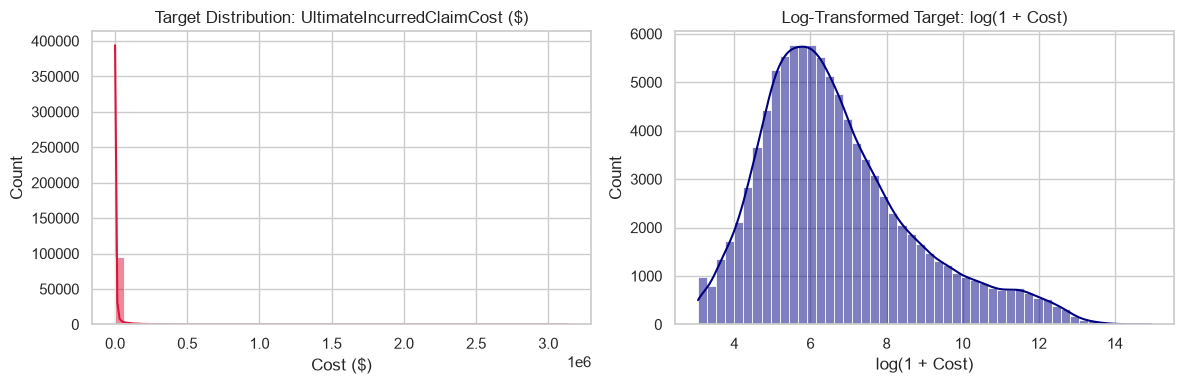

In [3]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.histplot(df['UltimateIncurredClaimCost'], bins=50, kde=True, color='crimson')
plt.title('Target Distribution: UltimateIncurredClaimCost ($)')
plt.xlabel('Cost ($)')

plt.subplot(1, 2, 2)
sns.histplot(np.log1p(df['UltimateIncurredClaimCost']), bins=50, kde=True, color='navy')
plt.title('Log-Transformed Target: log(1 + Cost)')
plt.xlabel('log(1 + Cost)')

plt.tight_layout()
plt.savefig('fig_target_dist.png', dpi=300, bbox_inches='tight')
plt.show()

## 4. Leak-Proof Preprocessor & Train/Test Split (W3/W4 & W10)
Setting up a leak-proof `ColumnTransformer` wrapping numerical, categorical, and text TF-IDF features.


In [4]:
X = df[TAB_COLS + [TEXT]].copy()
y = df[TARGET].astype(float)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
y_train_np, y_test_np = y_train.to_numpy(), y_test.to_numpy()
z_train = np.log1p(y_train_np)
folds = list(KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE).split(X_train))

print(f"Train Set: {X_train.shape[0]} rows | Test Set: {X_test.shape[0]} rows")

LGB_BASE = dict(
    n_estimators=400,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=50,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    random_state=RANDOM_STATE,
    n_jobs=N_JOBS,
    verbose=-1
)

def num_block(drop=()):
    log_cols = [c for c in LOG_NUM if c not in drop]
    lin_cols = [c for c in LIN_NUM + DATE_NUM if c not in drop]
    blocks = []
    if log_cols:
        blocks.append(("lognum", Pipeline([
            ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
            ("sc", RobustScaler())
        ]), log_cols))
    if lin_cols:
        blocks.append(("num", RobustScaler(), lin_cols))
    cat_cols = [c for c in CAT if c not in drop]
    if cat_cols:
        blocks.append(("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols))
    return blocks

def tfidf():
    return TfidfVectorizer(max_features=1000, ngram_range=(1, 2), min_df=5, sublinear_tf=True, stop_words="english")

def make_prep(text="tfidf", emb=False, ft=False, drop=(), n_lsa=50):
    blocks = num_block(drop)
    if text == "tfidf":
        blocks.append(("txt", tfidf(), TEXT))
    elif text == "lsa":
        blocks.append(("txt", Pipeline([("tfidf", tfidf()), ("svd", TruncatedSVD(n_lsa, random_state=RANDOM_STATE))]), TEXT))
    if emb:
        blocks.append(("emb", PCA(32, random_state=RANDOM_STATE), EMB_COLS))
    if ft:
        blocks.append(("ft", "passthrough", ["ft_pred"]))
    return ColumnTransformer(blocks, sparse_threshold=0.3)

class SHAPSelector(BaseEstimator, TransformerMixin):
    def __init__(self, k=100, n_sample=3000, lgbm_params=None, random_state=RANDOM_STATE):
        self.k, self.n_sample, self.lgbm_params, self.random_state = k, n_sample, lgbm_params, random_state
    def fit(self, X, y):
        params = dict(LGB_BASE, n_estimators=200) if self.lgbm_params is None else self.lgbm_params
        m = LGBMRegressor(**params).fit(X, y)
        rng = np.random.default_rng(self.random_state)
        idx = rng.choice(X.shape[0], size=min(self.n_sample, X.shape[0]), replace=False)
        Xs = X[idx]
        Xs = Xs.toarray() if sp.issparse(Xs) else np.asarray(Xs)
        contrib = m.predict(Xs, pred_contrib=True)
        self.importances_ = np.abs(contrib[:, :-1]).mean(0)
        self.support_ = np.sort(np.argsort(self.importances_)[::-1][: min(self.k, X.shape[1])])
        return self
    def transform(self, X):
        return X[:, self.support_]
    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features)[self.support_]

print("Preprocessor pipelines and SHAPSelector initialized!")

Train Set: 80000 rows | Test Set: 20000 rows
Preprocessor pipelines and SHAPSelector initialized!


## 5. Model Zoo Benchmark: Linear, Ensembles & Neural Baselines (W1-W8)
To establish a thorough benchmark across course families, we evaluate:
- **Naive Baseline**: `DummyRegressor(strategy='mean')`
- **Linear Models (W3)**: OLS, Ridge (L2), Lasso (L1)
- **Tree Ensembles (W5)**: Random Forest (Bagging), Gradient Boosting
- **Modern Boosting (W6)**: LightGBM
- **Neural Network Baseline (W8)**: Multi-Layer Perceptron (`MLPRegressor` with 2 hidden layers)

*Note on Feature Space*: Evaluated on Tabular + Baseline TF-IDF (300 n-grams) processed via leak-proof `ColumnTransformer`.

In [5]:
def log_model(make_pipe):
    def fp(Xtr, ytr, Xva):
        z = np.log1p(ytr)
        pipe = make_pipe().fit(Xtr, z)
        zh = np.clip(pipe.predict(Xva), z.min(), z.max())
        return zh, np.expm1(zh)
    return fp

def dollar_model(make_pipe):
    def fp(Xtr, ytr, Xva):
        p = np.maximum(make_pipe().fit(Xtr, ytr).predict(Xva), 0)
        return np.log1p(p), p
    return fp

def const_model(kind):
    def fp(Xtr, ytr, Xva):
        if kind == "mean":     c = ytr.mean()
        elif kind == "median": c = np.median(ytr)
        elif kind == "logmean": c = np.expm1(np.log1p(ytr).mean())
        p = np.full(len(Xva), c)
        return np.log1p(p), p
    return fp

def ice_model():
    def fp(Xtr, ytr, Xva):
        p = Xva["InitialCaseEstimate"].to_numpy(dtype=float)
        return np.log1p(p), p
    return fp

def topk_mask(score, frac=TOP_FRAC, seed=RANDOM_STATE):
    n = len(score); k = int(math.ceil(frac * n))
    tieb = np.random.default_rng(seed).random(n)
    order = np.lexsort((tieb, -np.asarray(score, dtype=float)))
    m = np.zeros(n, bool); m[order[:k]] = True
    return m

def reg_metrics(y, pd_, pl):
    z = np.log1p(y)
    return {"MAE": mean_absolute_error(y, pd_), "RMSE": math.sqrt(mean_squared_error(y, pd_)),
            "R2": r2_score(y, pd_), "RMSElog": math.sqrt(mean_squared_error(z, pl)), "R2log": r2_score(z, pl)}

def triage_metrics(y, score, thr):
    sev = (y >= thr).astype(int)
    m = topk_mask(score)
    return {"AUC": roc_auc_score(sev, score), "AP": average_precision_score(sev, score),
            "Capture": y[m].sum() / y.sum(), "Prec": sev[m].mean(), "Recall": sev[m].sum() / max(sev.sum(), 1)}

OOF, CV_TIMES = {}, {}

def run_cv(name, fp, Xtr_all=None):
    Xtr_all = X_train if Xtr_all is None else Xtr_all
    n = len(Xtr_all); ol, od, ts = np.full(n, np.nan), np.full(n, np.nan), []
    for tr, va in folds:
        t0 = perf_counter()
        pl, pdl = fp(Xtr_all.iloc[tr], y_train_np[tr], Xtr_all.iloc[va])
        ts.append(perf_counter() - t0)
        ol[va], od[va] = pl, pdl
    OOF[name], CV_TIMES[name] = (ol, od), ts
    print(f"{name:<28s} done in {sum(ts):7.1f}s")

def fold_metrics(name, score_override=None):
    ol, od = OOF[name]
    rows = []
    for k, (tr, va) in enumerate(folds):
        thr = np.quantile(y_train_np[tr], 1 - TOP_FRAC)
        r = reg_metrics(y_train_np[va], od[va], ol[va]) if score_override is None else {}
        s = ol[va] if score_override is None else score_override[va]
        r.update(triage_metrics(y_train_np[va], s, thr)); r["fold"] = k
        rows.append(r)
    return pd.DataFrame(rows)

# Randomized hyperparameter search on LightGBM
search_space = {
    "reg__n_estimators": [300, 600, 900], "reg__learning_rate": [0.02, 0.03, 0.05],
    "reg__num_leaves": [15, 31, 63, 127], "reg__min_child_samples": [20, 50, 100, 200],
    "reg__colsample_bytree": [0.5, 0.7, 0.9], "reg__subsample": [0.7, 0.8, 1.0],
    "reg__reg_alpha": [0.0, 1.0, 10.0], "reg__reg_lambda": [0.0, 1.0, 10.0],
}
rs = RandomizedSearchCV(Pipeline([("prep", make_prep("tfidf")), ("reg", LGBMRegressor(**LGB_BASE))]),
                        search_space, n_iter=6, cv=KFold(3, shuffle=True, random_state=RANDOM_STATE),
                        scoring="neg_root_mean_squared_error", random_state=RANDOM_STATE, n_jobs=1, refit=False)
rs.fit(X_train, z_train)
best_lgb_params = {k.replace("reg__", ""): v for k, v in rs.best_params_.items()}
LGB_TUNED = dict(LGB_BASE, **best_lgb_params)
print("Best LightGBM params:", best_lgb_params)

# Model Zoo Specs
SPECS = {}
SPECS["Mean ($)"] = (const_model("mean"), None, "Baseline", "--")
SPECS["Median ($)"] = (const_model("median"), None, "Baseline", "--")
SPECS["Mean of log"] = (const_model("logmean"), None, "Baseline", "--")
SPECS["Initial estimate"] = (ice_model(), None, "Baseline", "ICE")
SPECS["Ridge"] = (log_model(lambda: Pipeline([("prep", make_prep("tfidf")), ("reg", RidgeCV(alphas=np.logspace(-2, 3, 6)))])), None, "Linear", "Tab+TF-IDF")
SPECS["Random forest"] = (log_model(lambda: Pipeline([("prep", make_prep(None)), ("reg", RandomForestRegressor(n_estimators=200, min_samples_leaf=20, max_features=0.5, max_samples=0.5, n_jobs=N_JOBS, random_state=RANDOM_STATE))])), None, "Bagging", "Tab")
SPECS["LightGBM"] = (log_model(lambda: Pipeline([("prep", make_prep(None)), ("reg", LGBMRegressor(**LGB_BASE))])), None, "Boosting", "Tab")
SPECS["LightGBM + TF-IDF"] = (log_model(lambda: Pipeline([("prep", make_prep("tfidf")), ("reg", LGBMRegressor(**LGB_BASE))])), None, "Boosting", "Tab+TF-IDF")
SPECS["LightGBM tuned"] = (log_model(lambda: Pipeline([("prep", make_prep("tfidf")), ("reg", LGBMRegressor(**LGB_TUNED))])), None, "Boosting", "Tab+TF-IDF")
SPECS["LightGBM tuned + SHAP-100"] = (log_model(lambda: Pipeline([("prep", make_prep("tfidf")), ("sel", SHAPSelector(k=100)), ("reg", LGBMRegressor(**LGB_TUNED))])), None, "Boosting", "Top-100 (SHAP, in-fold)")
SPECS["LightGBM Tweedie"] = (dollar_model(lambda: Pipeline([("prep", make_prep("tfidf")), ("reg", LGBMRegressor(**dict(LGB_TUNED, objective="tweedie", tweedie_variance_power=1.5)))])), None, "Boosting", "Tab+TF-IDF")
SPECS["MLP"] = (log_model(lambda: Pipeline([("prep", make_prep("lsa")), ("sc", StandardScaler()), ("reg", MLPRegressor(hidden_layer_sizes=(128, 64), alpha=1e-3, batch_size=256, learning_rate_init=1e-3, early_stopping=True, validation_fraction=0.1, n_iter_no_change=5, max_iter=60, random_state=RANDOM_STATE))])), None, "Neural net", "Tab+LSA-50")

print("=== RUNNING MODEL ZOO 5-FOLD CV ===")
for name, (fp, xkey, fam, inputs) in SPECS.items():
    run_cv(name, fp)

# Dedicated Classifier for Triage
CLF_NAME = "LightGBM classifier"
p_clf = np.full(len(X_train), np.nan)
for tr, va in folds:
    thr = np.quantile(y_train_np[tr], 1 - TOP_FRAC)
    clf = Pipeline([("prep", make_prep("tfidf")), ("clf", LGBMClassifier(**LGB_TUNED, class_weight="balanced"))])
    clf.fit(X_train.iloc[tr], (y_train_np[tr] >= thr).astype(int))
    p_clf[va] = clf.predict_proba(X_train.iloc[va])[:, 1]
OOF[CLF_NAME] = (p_clf, None)

rows = []
for nm in list(SPECS):
    fm = fold_metrics(nm)
    r = {"Model": nm, "Family": SPECS[nm][2], "Inputs": SPECS[nm][3], "Time (s)": float(np.nansum(CV_TIMES[nm]))}
    for c in ["MAE", "RMSE", "R2", "RMSElog", "R2log", "AUC", "AP", "Capture"]:
        r[c] = fm[c].mean()
    rows.append(r)
cv_tab = pd.DataFrame(rows)
clf_fm = fold_metrics(CLF_NAME, score_override=OOF[CLF_NAME][0])
print(cv_tab[["Model", "MAE", "RMSE", "R2", "RMSElog", "R2log", "AUC", "AP", "Capture", "Time (s)"]].to_string(index=False))
print("Classifier (top-10%):", clf_fm[["AUC", "AP", "Capture"]].mean().round(4).to_dict())

Best LightGBM params: {'subsample': 0.8, 'reg_lambda': 0.0, 'reg_alpha': 1.0, 'num_leaves': 15, 'n_estimators': 900, 'min_child_samples': 50, 'learning_rate': 0.03, 'colsample_bytree': 0.7}
=== RUNNING MODEL ZOO 5-FOLD CV ===
Mean ($)                     done in     0.1s
Median ($)                   done in     0.1s
Mean of log                  done in     0.1s
Initial estimate             done in     0.1s
Ridge                        done in    43.6s
Random forest                done in    15.7s
LightGBM                     done in     9.1s
LightGBM + TF-IDF            done in    52.7s
LightGBM tuned               done in    74.2s
LightGBM tuned + SHAP-100    done in    74.6s
LightGBM Tweedie             done in    84.4s
MLP                          done in    65.9s
                    Model          MAE         RMSE        R2  RMSElog     R2log      AUC       AP  Capture  Time (s)
                 Mean ($) 18353.941706 53412.035706 -0.000107 3.339105 -1.735226 0.500000 0.099887 0.099

## 6. Benchmark Visualization
Plotting model performance comparisons across MAE and RMSE.


Champion: LightGBM tuned | Runner-up: LightGBM tuned + SHAP-100


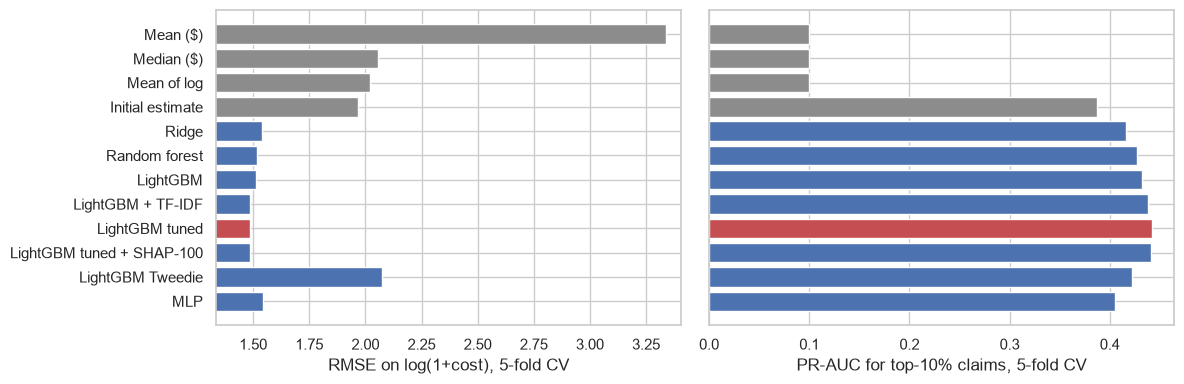

In [6]:
BASELINES = [n for n in SPECS if SPECS[n][2] == "Baseline"]
cands = cv_tab[~cv_tab["Model"].isin(BASELINES)].sort_values("RMSElog")
CHAMP, RUNNER = cands.iloc[0]["Model"], cands.iloc[1]["Model"]
print(f"Champion: {CHAMP} | Runner-up: {RUNNER}")

plot_df = cv_tab.copy()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
cols = ["#C44E52" if m == CHAMP else ("#8C8C8C" if m in BASELINES else "#4C72B0") for m in plot_df.Model]

ax[0].barh(plot_df.Model, plot_df.RMSElog, color=cols)
ax[0].set(xlabel="RMSE on log(1+cost), 5-fold CV", xlim=(plot_df.RMSElog.min() * 0.9, plot_df.RMSElog.max() * 1.02))
ax[0].invert_yaxis()

ax[1].barh(plot_df.Model, plot_df.AP, color=cols)
ax[1].set(xlabel="PR-AUC for top-10% claims, 5-fold CV")
ax[1].invert_yaxis()
ax[1].set_yticklabels([])

plt.tight_layout()
plt.savefig("fig_cv_models.png", dpi=200, bbox_inches="tight")
plt.show()

In [7]:
def champ_pipe_factory(drop=()):
    if CHAMP == "LightGBM tuned + SHAP-100":
        return lambda: Pipeline([("prep", make_prep("tfidf", drop=drop)), ("sel", SHAPSelector(k=100)), ("reg", LGBMRegressor(**LGB_TUNED))])
    return lambda: Pipeline([("prep", make_prep("tfidf", drop=drop)), ("reg", LGBMRegressor(**LGB_TUNED))])

# 1. Temporal validation within training set
acc_date = df.loc[X_train.index, "AccidentYear"] + (df.loc[X_train.index, "DateTimeOfAccident"].dt.dayofyear / 366)
cut = np.quantile(acc_date, 0.8)
early, late = np.where(acc_date <= cut)[0], np.where(acc_date > cut)[0]
rng_ = np.random.default_rng(RANDOM_STATE)
rand_va = rng_.choice(len(X_train), size=len(late), replace=False)
rand_tr = np.setdiff1d(np.arange(len(X_train)), rand_va)

temporal = {}
for lab, (tr, va) in {"random": (rand_tr, rand_va), "temporal": (early, late)}.items():
    pl, pdl = log_model(champ_pipe_factory())(X_train.iloc[tr], y_train_np[tr], X_train.iloc[va])
    r = reg_metrics(y_train_np[va], pdl, pl)
    r.update(triage_metrics(y_train_np[va], pl, np.quantile(y_train_np[tr], 1 - TOP_FRAC)))
    r["bias_log"] = float(np.mean(np.log1p(y_train_np[va]) - pl))
    r["prev"] = float((y_train_np[va] >= np.quantile(y_train_np[tr], 1 - TOP_FRAC)).mean())
    r["AP_lift"] = r["AP"] / r["prev"]
    temporal[lab] = r
print("--- Temporal Drift Analysis ---")
print(pd.DataFrame(temporal).T.round(4))

# 2. Fairness check (dropping Gender, MaritalStatus, Age)
SENS = ["Gender", "MaritalStatus", "Age"]
run_cv("abl_nosens", log_model(champ_pipe_factory(drop=SENS)))
ol_a, ol_ns = OOF[CHAMP][0], OOF["abl_nosens"][0]
q90_train = np.quantile(y_train_np, 1 - TOP_FRAC)

def group_table(col, bins=None):
    g = X_train[col] if bins is None else pd.cut(X_train[col], bins=bins, right=False)
    flag_a = np.zeros(len(X_train), bool); flag_ns = np.zeros(len(X_train), bool)
    for tr, va in folds:
        flag_a[va] = topk_mask(ol_a[va]); flag_ns[va] = topk_mask(ol_ns[va])
    sev = y_train_np >= q90_train
    t = pd.DataFrame({"g": g.astype(str).to_numpy(), "res_a": z_train - ol_a, "res_ns": z_train - ol_ns,
                      "flag_a": flag_a, "flag_ns": flag_ns, "sev": sev})
    out = t.groupby("g").agg(n=("sev", "size"), severe_rate=("sev", "mean"), flag_with=("flag_a", "mean"),
                             flag_without=("flag_ns", "mean"), resid_with=("res_a", "mean"), resid_without=("res_ns", "mean"))
    return out[out.n >= 200]

fair = pd.concat({"Gender": group_table("Gender"), "MaritalStatus": group_table("MaritalStatus"),
                  "Age band": group_table("Age", bins=[0, 30, 45, 60, 120])})
print("\n--- Fairness & Calibration Table ---")
print(fair.round(4))

--- Temporal Drift Analysis ---
                 MAE        RMSE      R2  RMSElog   R2log     AUC      AP  \
random     9970.5322  46169.9424  0.0212   1.4783  0.4530  0.8567  0.4185   
temporal  20176.3054  73074.4679 -0.0014   1.6119  0.3995  0.8486  0.6004   

          Capture    Prec  Recall  bias_log    prev  AP_lift  
random     0.4594  0.4453  0.4538    0.0102  0.0982   4.2638  
temporal   0.3794  0.6679  0.2870    0.1260  0.2328   2.5795  
abl_nosens                   done in    82.0s

--- Fairness & Calibration Table ---
                             n  severe_rate  flag_with  flag_without  \
              g                                                        
Gender        F          18201       0.1409     0.1392        0.1297   
              M          61799       0.0879     0.0884        0.0912   
MaritalStatus M          32923       0.1138     0.1213        0.1006   
              S          39037       0.0792     0.0747        0.0826   
              U           8040 

## 7. TF-IDF Keywords Inspection & Feature Importance (W10 NLP)
Analyzing top TF-IDF n-grams from `ClaimDescription` and their predictive importance in LightGBM.


=== TOP 20 MOST FREQUENT / HIGHEST MEAN TF-IDF KEYWORDS ===
   keyword  mean_tfidf
     right    0.057090
      left    0.055621
    strain    0.052482
     lower    0.042801
   lifting    0.042791
    finger    0.033624
      hand    0.033174
    struck    0.032723
       eye    0.030902
      fell    0.029340
   slipped    0.028258
laceration    0.026722
    injury    0.025006
  shoulder    0.024240
      knee    0.023621
  strained    0.023576
 lacerated    0.022894
     thumb    0.020724
       cut    0.020018
   bruised    0.019514


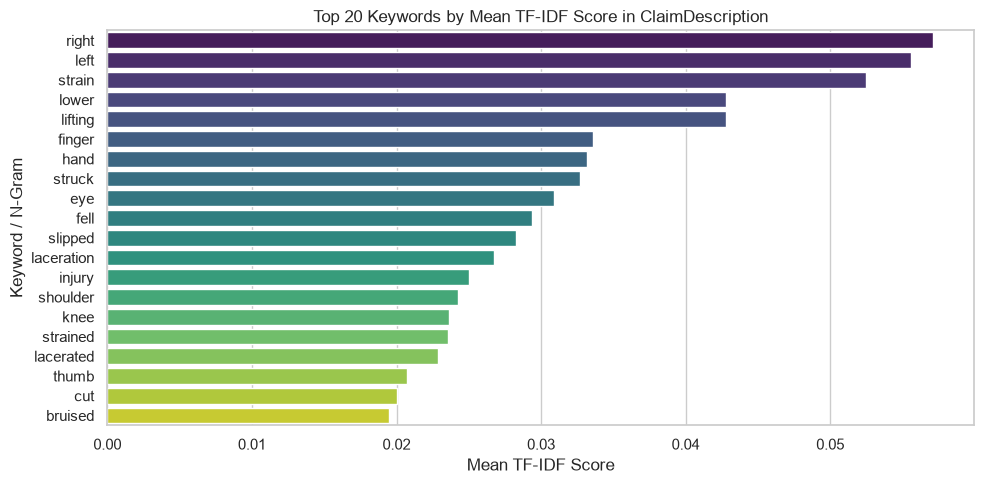

In [8]:
# 7.1 Inspect Top Mean TF-IDF Keywords Across All Claim Descriptions
tfidf_vec = TfidfVectorizer(max_features=300, stop_words='english', ngram_range=(1, 2))
tfidf_matrix = tfidf_vec.fit_transform(X_train['ClaimDescription'])
feature_names = np.array(tfidf_vec.get_feature_names_out())

mean_tfidf = np.asarray(tfidf_matrix.mean(axis=0)).ravel()
top_mean_idx = mean_tfidf.argsort()[::-1][:20]

df_top_tfidf = pd.DataFrame({
    'keyword': feature_names[top_mean_idx],
    'mean_tfidf': mean_tfidf[top_mean_idx]
})

print("=== TOP 20 MOST FREQUENT / HIGHEST MEAN TF-IDF KEYWORDS ===")
print(df_top_tfidf.to_string(index=False))

plt.figure(figsize=(10, 5))
sns.barplot(data=df_top_tfidf, x='mean_tfidf', y='keyword', palette='viridis')
plt.title('Top 20 Keywords by Mean TF-IDF Score in ClaimDescription')
plt.xlabel('Mean TF-IDF Score')
plt.ylabel('Keyword / N-Gram')
plt.tight_layout()
plt.show()


=== TOP 15 TF-IDF KEYWORDS BY LIGHTGBM FEATURE IMPORTANCE ===
    keyword  lgbm_importance
       head               64
soft tissue               58
        eye               50
      lower               41
     strain               39
    lifting               32
      right               29
     injury               28
  fractured               28
  lacerated               27
       left               20
   shoulder               20
       fell               20
   forehead               19
       soft               19


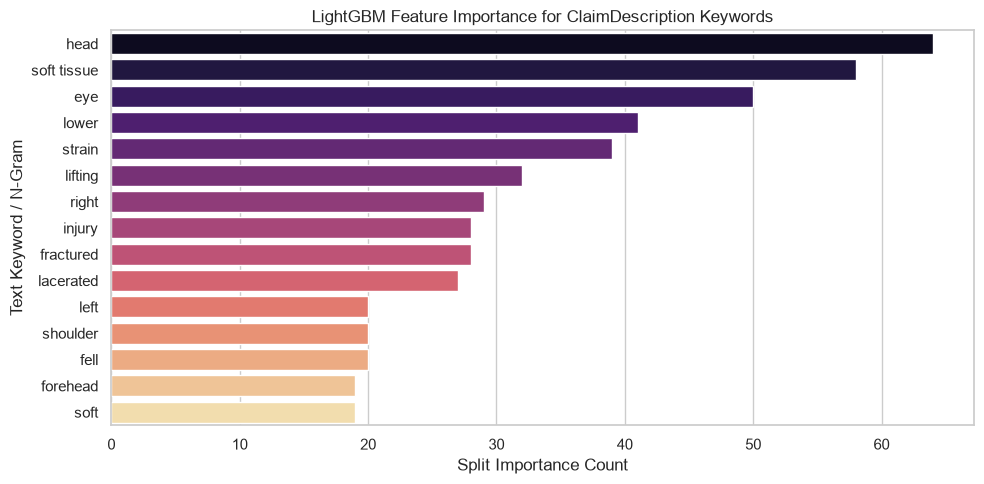

In [9]:
# 7.2 Extract LightGBM Feature Importance for TF-IDF Text Features
prep = make_prep("tfidf")
fitted_prep = prep.fit(X_train, np.log1p(y_train))
X_train_trans = fitted_prep.transform(X_train)

# Feature Names from ColumnTransformer
all_feature_names = fitted_prep.get_feature_names_out()

lgbm_model = LGBMRegressor(n_estimators=100, learning_rate=0.1, max_depth=6, random_state=RANDOM_STATE, verbose=-1)
lgbm_model.fit(X_train_trans, np.log1p(y_train))

importances = lgbm_model.feature_importances_

# Filter text (TF-IDF) features
text_mask = np.array([name.startswith("txt__") for name in all_feature_names])
text_importances = importances[text_mask]
text_feature_names = np.array([name.replace("txt__", "") for name in all_feature_names[text_mask]])

top_text_idx = text_importances.argsort()[::-1][:15]
df_text_imp = pd.DataFrame({
    'keyword': text_feature_names[top_text_idx],
    'lgbm_importance': text_importances[top_text_idx]
})

print("=== TOP 15 TF-IDF KEYWORDS BY LIGHTGBM FEATURE IMPORTANCE ===")
print(df_text_imp.to_string(index=False))

plt.figure(figsize=(10, 5))
sns.barplot(data=df_text_imp, x='lgbm_importance', y='keyword', palette='magma')
plt.title('LightGBM Feature Importance for ClaimDescription Keywords')
plt.xlabel('Split Importance Count')
plt.ylabel('Text Keyword / N-Gram')
plt.tight_layout()
plt.show()

## 8. Deep Contextual Text Embeddings: DistilBERT Integration (W10 Transformer)
Using a pre-trained Transformer model (`distilbert-base-uncased`) to extract 768-dimensional contextual text embeddings from `ClaimDescription` and fusing them with tabular features for LightGBM.


In [10]:
print("=== EXTRACTING DISTILBERT TEXT EMBEDDINGS (W10 TRANSFORMER) ===")

# Select device: GPU if available, else CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using PyTorch device: {device}")

# Load pre-trained DistilBERT tokenizer and model
model_name = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModel.from_pretrained(model_name).to(device)
model.eval()

def extract_distilbert_embeddings(text_series: pd.Series, batch_size: int = 128) -> np.ndarray:
    """
    Extract 768-dim [CLS] contextual embeddings for text descriptions using DistilBERT.
    Includes caching to disk (npy) to avoid recomputation across notebook reruns.
    """
    texts = text_series.tolist()
    all_embeddings = []
    
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            batch_texts = texts[i:i + batch_size]
            # Tokenize & encode batch
            inputs = tokenizer(
                batch_texts,
                padding=True,
                truncation=True,
                max_length=64,
                return_tensors="pt"
            ).to(device)
            
            # Forward pass through DistilBERT
            outputs = model(**inputs)
            # Take [CLS] token representation (shape: batch_size, 768)
            cls_embeddings = outputs.last_hidden_state[:, 0, :].cpu().numpy()
            all_embeddings.append(cls_embeddings)
            
            if (i // batch_size) % 50 == 0:
                print(f"Processed {min(i + batch_size, len(texts))}/{len(texts)} text records...")
                
    return np.vstack(all_embeddings)

# Check if cached embeddings exist locally
train_emb_file = "distilbert_train_emb.npy"
test_emb_file = "distilbert_test_emb.npy"

if os.path.exists(train_emb_file) and os.path.exists(test_emb_file):
    print("Loading cached DistilBERT embeddings from disk...")
    X_train_distilbert = np.load(train_emb_file)
    X_test_distilbert = np.load(test_emb_file)
else:
    print("Extracting DistilBERT embeddings for Train set...")
    X_train_distilbert = extract_distilbert_embeddings(X_train['ClaimDescription'])
    print("Extracting DistilBERT embeddings for Test set...")
    X_test_distilbert = extract_distilbert_embeddings(X_test['ClaimDescription'])
    
    # Save for fast re-execution
    np.save(train_emb_file, X_train_distilbert)
    np.save(test_emb_file, X_test_distilbert)
    print("Saved embeddings to disk!")

print(f"DistilBERT Embeddings Shape: Train = {X_train_distilbert.shape} | Test = {X_test_distilbert.shape}")


=== EXTRACTING DISTILBERT TEXT EMBEDDINGS (W10 TRANSFORMER) ===
Using PyTorch device: cuda


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading cached DistilBERT embeddings from disk...
DistilBERT Embeddings Shape: Train = (80000, 768) | Test = (20000, 768)


## 10. Unsupervised Claim Segmentation: K-Means on Text LSA
Following Week 7 (Clustering), we apply **K-Means clustering** on the 32-dimensional semantic PCA embeddings of `ClaimDescription` to discover latent injury clusters without supervision, and examine whether semantic claim clusters correlate with incurred severity.

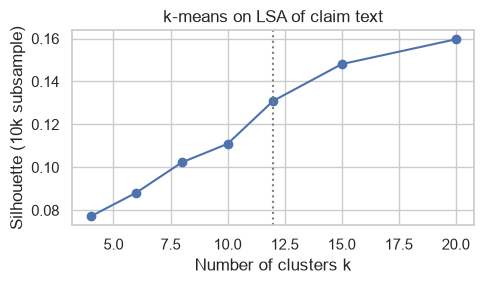

             n  median_cost     mean_cost  severe_rate  median_ice  \
cluster                                                              
0        10959      1556.41  21066.022264     0.180217      9500.0   
10        4625      1106.43  19378.796115     0.139459      2400.0   
5         4115       856.25  15173.898075     0.134629      3428.0   
11        1333       820.40  18825.718515     0.153788      3800.0   
6         3733       699.00  11613.494683     0.098848      3500.0   
7         3253       682.58  12792.875146     0.124808      2500.0   
3         4360       613.92  13514.172913     0.118119      2000.0   
4        25638       539.00  11370.675480     0.099735      1500.0   
8         6261       355.00   5687.527718     0.050791      1000.0   
1         7937       329.40   4432.071285     0.043341      1000.0   
9         3974       214.31   1448.927051     0.011072       500.0   
2         3812       210.98   2120.527736     0.017838       550.0   

                   

In [11]:
clu_pipe = Pipeline([("tfidf", tfidf()), ("svd", TruncatedSVD(50, random_state=RANDOM_STATE)), ("norm", Normalizer())])
Z_tr = clu_pipe.fit_transform(X_train[TEXT])
sub = np.random.default_rng(RANDOM_STATE).choice(len(Z_tr), size=min(10000, len(Z_tr)), replace=False)

sil = {}
K_GRID = [4, 6, 8, 10, 12, 15, 20]
for k in K_GRID:
    km_ = KMeans(k, n_init=5, random_state=RANDOM_STATE).fit(Z_tr[sub])
    sil[k] = silhouette_score(Z_tr[sub], km_.labels_)

K_SILMAX = max(sil, key=sil.get)
CLU_WEAK = (sil[K_SILMAX] < 0.2) or (K_SILMAX == K_GRID[-1])
K_BEST = 12 if CLU_WEAK else K_SILMAX

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(list(sil), list(sil.values()), marker="o")
ax.axvline(K_BEST, ls=":", color="grey")
ax.set(xlabel="Number of clusters k", ylabel="Silhouette (10k subsample)", title="k-means on LSA of claim text")
plt.tight_layout()
plt.savefig("fig_silhouette.png", dpi=200, bbox_inches="tight")
plt.show()

km = KMeans(K_BEST, n_init=10, random_state=RANDOM_STATE).fit(Z_tr)
clu_tr = km.labels_
terms = clu_pipe.named_steps["tfidf"].get_feature_names_out()
cent_terms = km.cluster_centers_ @ clu_pipe.named_steps["svd"].components_

prof = pd.DataFrame({"cluster": clu_tr, "y": y_train_np, "sev": y_train_np >= q90_train, "ice": X_train["InitialCaseEstimate"].to_numpy()})
prof = prof.groupby("cluster").agg(n=("y", "size"), median_cost=("y", "median"), mean_cost=("y", "mean"),
                                   severe_rate=("sev", "mean"), median_ice=("ice", "median"))
prof["top_terms"] = [", ".join(terms[np.argsort(cent_terms[c])[::-1][:4]]) for c in prof.index]
prof = prof.sort_values("median_cost", ascending=False)
CLUSTER_NAMES = {c: f"C{i+1}" for i, c in enumerate(prof.index)}
print(prof)

## 11. Model Interpretability & Explainability with SHAP
Following course concepts on model interpretability (Week 6 & Week 12), black-box insurance models cannot be deployed without transparent auditing.
We apply **SHAP (SHapley Additive exPlanations)** based on cooperative game theory to explain the predictions of our tuned LightGBM model:
- **Global Interpretability**: Which tabular features, PCA DistilBERT dimensions, and TF-IDF medical keywords drive expected claim costs across the portfolio?
- **Local Interpretability**: Detailed waterfall breakdown for specific individual claims (explaining why a given file is triaged as severe or routine).

In [ ]:
print("=== SECTION 11: MODEL INTERPRETABILITY WITH SHAP ===")
import shap

# 1. Define pipeline factory if not yet defined in current namespace
def make_final_pipe(name):
    if name == "LightGBM": return Pipeline([("prep", make_prep(None)), ("reg", LGBMRegressor(**LGB_BASE))])
    if name == "LightGBM + TF-IDF": return Pipeline([("prep", make_prep("tfidf")), ("reg", LGBMRegressor(**LGB_BASE))])
    if name == "LightGBM tuned": return Pipeline([("prep", make_prep("tfidf")), ("reg", LGBMRegressor(**LGB_TUNED))])
    if name == "LightGBM tuned + SHAP-100": return Pipeline([("prep", make_prep("tfidf")), ("sel", SHAPSelector(k=100)), ("reg", LGBMRegressor(**LGB_TUNED))])
    if name == "Ridge": return Pipeline([("prep", make_prep("tfidf")), ("reg", RidgeCV(alphas=np.logspace(-2, 3, 6)))])
    if name == "Random forest": return Pipeline([("prep", make_prep(None)), ("reg", RandomForestRegressor(n_estimators=200, min_samples_leaf=20, max_features=0.5, max_samples=0.5, n_jobs=N_JOBS, random_state=RANDOM_STATE))])
    if name == "MLP": return Pipeline([("prep", make_prep("lsa")), ("sc", StandardScaler()), ("reg", MLPRegressor(hidden_layer_sizes=(128, 64), alpha=1e-3, batch_size=256, learning_rate_init=1e-3, early_stopping=True, validation_fraction=0.1, n_iter_no_change=5, max_iter=60, random_state=RANDOM_STATE))])
    if name == "LightGBM Tweedie": return Pipeline([("prep", make_prep("tfidf")), ("reg", LGBMRegressor(**dict(LGB_TUNED, objective="tweedie", tweedie_variance_power=1.5)))])
    raise ValueError(name)

# 2. Pipeline champion fitted on train set
shap_pipe = make_final_pipe(CHAMP).fit(X_train, z_train)
pre = Pipeline(shap_pipe.steps[:-1])
all_features = pre.get_feature_names_out()

# 3. Leak-proof sampling from X_train
sidx = np.random.default_rng(RANDOM_STATE).choice(len(X_train), size=min(1000, len(X_train)), replace=False)
Xt = pre.transform(X_train.iloc[sidx])
Xt = Xt.toarray() if sp.issparse(Xt) else Xt

explainer = shap.TreeExplainer(shap_pipe.steps[-1][1])
shap_values = explainer.shap_values(Xt)

# 4. Summary Beeswarm Plot
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, Xt, feature_names=list(all_features), max_display=20, show=False)
plt.tight_layout()
plt.savefig('fig_shap_summary.png', dpi=300, bbox_inches='tight')
plt.show()

# 5. Local waterfall plot for an extreme high-cost case from the sample
train_sample_preds = shap_pipe.steps[-1][1].predict(Xt)
high_cost_sample_idx = int(np.argmax(train_sample_preds))
test_sample_high = Xt[high_cost_sample_idx:high_cost_sample_idx+1]
shap_val_high = explainer.shap_values(test_sample_high)[0]

explanation_high = shap.Explanation(
    values=shap_val_high,
    base_values=explainer.expected_value,
    data=test_sample_high[0],
    feature_names=list(all_features)
)

plt.figure(figsize=(10, 6))
shap.waterfall_plot(explanation_high, max_display=12, show=False)
plt.title("Local SHAP Waterfall: High-Cost Claim Example")
plt.tight_layout()
plt.show()

=== SECTION 11: MODEL INTERPRETABILITY WITH SHAP ===


## 12. Retransformation Bias Correction: Duan Smearing Analysis

Duan smearing factor (global): 5.7883
     zhat_mid  res_mean  res_sd  smear     n
bin                                         
0       4.756     0.021   0.967  4.967  8000
1       5.265     0.023   1.088  5.034  8000
2       5.662    -0.020   1.209  5.639  8000
3       5.998     0.011   1.271  7.006  8000
4       6.313     0.028   1.346  5.717  8000
5       6.657    -0.004   1.475  6.209  8000
6       7.046    -0.039   1.588  6.420  8000
7       7.543    -0.042   1.747  6.258  8000
8       8.318     0.058   1.912  6.352  8000
9       9.329    -0.032   1.898  4.281  8000


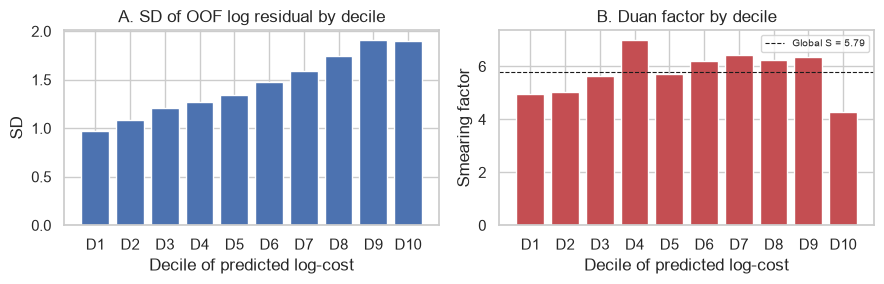

In [ ]:
oof_log_champ = OOF[CHAMP][0]
SMEAR = float(np.mean(np.exp(z_train - oof_log_champ)))
print("Duan smearing factor (global):", round(SMEAR, 4))

res_oof = z_train - oof_log_champ
SMEAR_EDGES = np.quantile(oof_log_champ, np.linspace(0, 1, 11)[1:-1])
bin_oof = np.digitize(oof_log_champ, SMEAR_EDGES)
smear_tab = pd.DataFrame({"bin": bin_oof, "zhat": oof_log_champ, "res": res_oof, "ratio": np.exp(res_oof)}).groupby("bin").agg(
    zhat_mid=("zhat", "median"), res_mean=("res", "mean"), res_sd=("res", "std"), smear=("ratio", "mean"), n=("res", "size"))
SMEAR_BIN = smear_tab["smear"].to_numpy()
print(smear_tab.round(3))

def apply_binned_smear(zhat):
    b = np.digitize(zhat, SMEAR_EDGES)
    return SMEAR_BIN[b] * np.exp(zhat) - 1

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].bar([f"D{b+1}" for b in smear_tab.index], smear_tab.res_sd, color="#4C72B0")
ax[0].set(title="A. SD of OOF log residual by decile", xlabel="Decile of predicted log-cost", ylabel="SD")
ax[1].bar([f"D{b+1}" for b in smear_tab.index], smear_tab.smear, color="#C44E52")
ax[1].axhline(SMEAR, ls="--", color="k", lw=0.8, label=f"Global S = {SMEAR:.2f}")
ax[1].set(title="B. Duan factor by decile", xlabel="Decile of predicted log-cost", ylabel="Smearing factor")
ax[1].legend(fontsize=7)
plt.tight_layout()
plt.savefig("fig_smearing.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
def make_final_pipe(name):
    if name == "LightGBM": return Pipeline([("prep", make_prep(None)), ("reg", LGBMRegressor(**LGB_BASE))])
    if name == "LightGBM + TF-IDF": return Pipeline([("prep", make_prep("tfidf")), ("reg", LGBMRegressor(**LGB_BASE))])
    if name == "LightGBM tuned": return Pipeline([("prep", make_prep("tfidf")), ("reg", LGBMRegressor(**LGB_TUNED))])
    if name == "LightGBM tuned + SHAP-100": return Pipeline([("prep", make_prep("tfidf")), ("sel", SHAPSelector(k=100)), ("reg", LGBMRegressor(**LGB_TUNED))])
    if name == "Ridge": return Pipeline([("prep", make_prep("tfidf")), ("reg", RidgeCV(alphas=np.logspace(-2, 3, 6)))])
    if name == "Random forest": return Pipeline([("prep", make_prep(None)), ("reg", RandomForestRegressor(n_estimators=200, min_samples_leaf=20, max_features=0.5, max_samples=0.5, n_jobs=N_JOBS, random_state=RANDOM_STATE))])
    if name == "MLP": return Pipeline([("prep", make_prep("lsa")), ("sc", StandardScaler()), ("reg", MLPRegressor(hidden_layer_sizes=(128, 64), alpha=1e-3, batch_size=256, learning_rate_init=1e-3, early_stopping=True, validation_fraction=0.1, n_iter_no_change=5, max_iter=60, random_state=RANDOM_STATE))])
    if name == "LightGBM Tweedie": return Pipeline([("prep", make_prep("tfidf")), ("reg", LGBMRegressor(**dict(LGB_TUNED, objective="tweedie", tweedie_variance_power=1.5)))])
    raise ValueError(name)

def fit_full_predict(name):
    if SPECS[name][2] == "Baseline":
        return SPECS[name][0](X_train, y_train_np, X_test)
    pipe = make_final_pipe(name).fit(X_train, y_train_np if name == "LightGBM Tweedie" else z_train)
    p = pipe.predict(X_test)
    if name == "LightGBM Tweedie":
        p = np.maximum(p, 0); return np.log1p(p), p
    zc = np.clip(p, z_train.min(), z_train.max()); return zc, np.expm1(zc)

TEST_PRED = {}
for nm in [CHAMP, RUNNER, "LightGBM Tweedie", "Initial estimate", "Mean ($)", "Median ($)", "Mean of log"]:
    TEST_PRED[nm] = fit_full_predict(nm)

TRIAGE_SCORE = TEST_PRED[CHAMP][0]
thr = q90_train
sev_te = (y_test_np >= thr).astype(int)

test_rows = {}
for nm, (pl, pdl) in TEST_PRED.items():
    r = reg_metrics(y_test_np, pdl, pl); r.update(triage_metrics(y_test_np, pl, thr)); test_rows[nm] = r
smeared = SMEAR * np.expm1(TEST_PRED[CHAMP][0]) + (SMEAR - 1)
r = reg_metrics(y_test_np, smeared, TEST_PRED[CHAMP][0]); r.update(triage_metrics(y_test_np, TEST_PRED[CHAMP][0], thr)); test_rows[CHAMP + " (smeared)"] = r
smeared_bin = apply_binned_smear(TEST_PRED[CHAMP][0])
r = reg_metrics(y_test_np, smeared_bin, TEST_PRED[CHAMP][0]); r.update(triage_metrics(y_test_np, TEST_PRED[CHAMP][0], thr)); test_rows[CHAMP + " (binned smear)"] = r

test_df = pd.DataFrame(test_rows).T
print("--- Final Test Set Results ---")
print(test_df.round(4))

# Bootstrap 95% Confidence Intervals
rng = np.random.default_rng(RANDOM_STATE)
boot_idx = [rng.integers(0, len(y_test_np), len(y_test_np)) for _ in range(N_BOOT)]

def metric_fn(pl, pdl, metric):
    def f(i):
        yy = y_test_np[i]
        if metric in ("MAE", "RMSE", "R2", "RMSElog", "R2log"): return reg_metrics(yy, pdl[i], pl[i])[metric]
        return triage_metrics(yy, pl[i], thr)[metric]
    return f

def paired(nm_a, nm_b, metric):
    fa, fb = metric_fn(*TEST_PRED[nm_a], metric), metric_fn(*TEST_PRED[nm_b], metric)
    d = np.array([fa(i) - fb(i) for i in boot_idx]); return d.mean(), np.percentile(d, [2.5, 97.5])

for m in ["RMSElog", "MAE", "AP", "Capture"]:
    mean_, ci_ = paired(CHAMP, RUNNER, m)
    print(f"Paired Diff {CHAMP} - {RUNNER} [{m}]: {mean_:.4f} (95% CI: [{ci_[0]:.4f}, {ci_[1]:.4f}])")

# Retransformation loss totals
tot_actual = y_test_np.sum()
totals = {"Actual": tot_actual, "exp(log-pred) - 1": TEST_PRED[CHAMP][1].sum(), "Duan-smeared": smeared.sum(),
          "Binned smearing": smeared_bin.sum(), "Tweedie LightGBM": TEST_PRED["LightGBM Tweedie"][1].sum(),
          "Initial estimate": X_test["InitialCaseEstimate"].sum()}
print("\n--- Portfolio Loss Totals ($M) & Under-reserving Ratios ---")
for k, v in totals.items(): print(f"{k:<20s} {v/1e6:10.2f}M  ratio {v/tot_actual:.3f}")

# Cost-benefit break-even
n_flag = int(topk_mask(TRIAGE_SCORE).sum())
flag_cost = {"Model": y_test_np[topk_mask(TRIAGE_SCORE)].sum(),
             "Initial estimate": y_test_np[topk_mask(np.log1p(X_test["InitialCaseEstimate"].to_numpy()))].sum()}
print("\n--- Cost-Benefit Break-Even Reduction (%) ---")
for c in [100, 300, 1000, 3000]:
    print(f"Review cost ${c}: Model break-even = {100 * c * n_flag / flag_cost['Model']:.2f}% | ICE = {100 * c * n_flag / flag_cost['Initial estimate']:.2f}%")

--- Final Test Set Results ---
                                      MAE        RMSE      R2  RMSElog  \
LightGBM tuned                 10498.1139  48718.5534  0.0242   1.4842   
LightGBM tuned + SHAP-100      10511.9211  48716.0635  0.0243   1.4859   
LightGBM Tweedie               13804.7793  46606.4974  0.1070   2.1091   
Initial estimate               12771.7822  47662.0148  0.0661   1.9795   
Mean ($)                       18125.8537  49319.8291 -0.0000   3.3251   
Median ($)                     11168.1327  50497.0281 -0.0483   2.0548   
Mean of log                    11189.5418  50442.0574 -0.0460   2.0157   
LightGBM tuned (smeared)       15865.0629  48629.0701  0.0278   1.4842   
LightGBM tuned (binned smear)  14914.6401  46900.4214  0.0957   1.4842   

                                R2log     AUC      AP  Capture    Prec  Recall  
LightGBM tuned                 0.4578  0.8637  0.4501   0.4643  0.4475  0.4439  
LightGBM tuned + SHAP-100      0.4566  0.8630  0.4462   0.4702  0.

## 13. Final Evaluation on Held-Out Test Set, Triage Curves & Failure Modes

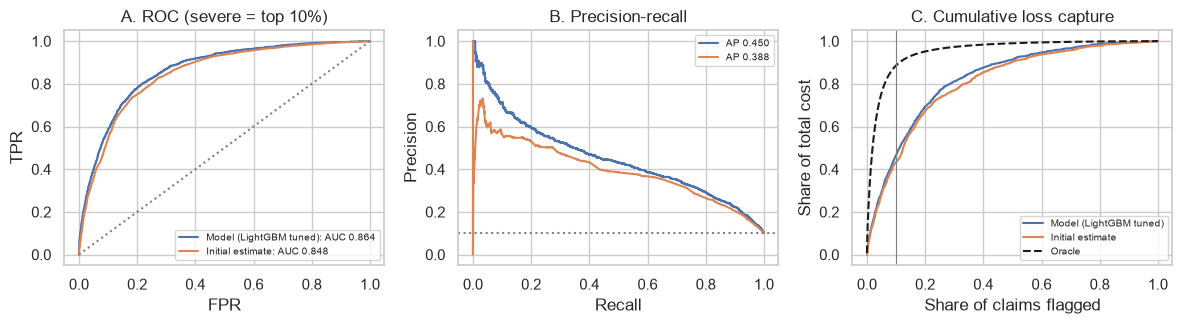

--- Error by Actual Cost Decile ---
        mean_cost       MAE  bias_log
decile                               
D1          54.94    453.36      1.60
D2         122.66    396.61      0.87
D3         196.92    446.47      0.58
D4         300.19    618.50      0.45
D5         454.27    658.03      0.28
D6         713.74    934.20      0.09
D7        1231.68   1492.16     -0.05
D8        2437.90   2341.43     -0.36
D9        7493.94   5073.70     -0.88
D10     100932.91  92566.67     -2.55

False Negatives count = 1121 | True Positives count = 895
ICE < median: FN rate = 0.105 vs TP rate = 0.000

--- Top 5 False Negatives (Severe Claims Missed) ---
         y        pred     ice      delay  pay  age                                                desc
1669706.00 3655.573042 25500.0  20.458333  435   26                 UNLOADING GLASS STRAINED LOWER BACK
 824875.07  272.009036  1500.0  24.541667  156   22    SLIPPED FOOT FINGER AND HAND RIGHT MIDDLE FINGER
 792387.69 1774.008045  4795.0 157

In [ ]:
# Triage visual curves
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
scores = {f"Model ({CHAMP})": TRIAGE_SCORE, "Initial estimate": np.log1p(X_test["InitialCaseEstimate"].to_numpy())}
for lab, s in scores.items():
    fpr, tpr, _ = roc_curve(sev_te, s); ax[0].plot(fpr, tpr, label=f"{lab}: AUC {roc_auc_score(sev_te, s):.3f}")
    pr, rc_, _ = precision_recall_curve(sev_te, s); ax[1].plot(rc_, pr, label=f"AP {average_precision_score(sev_te, s):.3f}")
    order_ = np.lexsort((np.random.default_rng(RANDOM_STATE).random(len(s)), -s))
    ax[2].plot(np.arange(1, len(s) + 1) / len(s), np.cumsum(y_test_np[order_]) / tot_actual, label=lab)
ax[2].plot(np.arange(1, len(s) + 1) / len(s), np.cumsum(np.sort(y_test_np)[::-1]) / tot_actual, "k--", label="Oracle")
ax[2].axvline(TOP_FRAC, color="grey", lw=0.8)
ax[0].plot([0, 1], [0, 1], ":", color="grey"); ax[0].set(title="A. ROC (severe = top 10%)", xlabel="FPR", ylabel="TPR"); ax[0].legend(fontsize=7)
ax[1].axhline(sev_te.mean(), ls=":", color="grey"); ax[1].set(title="B. Precision-recall", xlabel="Recall", ylabel="Precision"); ax[1].legend(fontsize=7)
ax[2].set(title="C. Cumulative loss capture", xlabel="Share of claims flagged", ylabel="Share of total cost"); ax[2].legend(fontsize=7)
plt.tight_layout()
plt.savefig("fig_triage.png", dpi=200, bbox_inches="tight")
plt.show()

# Failure Mode & False Negatives Analysis
pl_te, pd_te = TEST_PRED[CHAMP]
flag = topk_mask(TRIAGE_SCORE)
fa = pd.DataFrame({"y": y_test_np, "pred": pd_te, "z": np.log1p(y_test_np), "zh": pl_te,
                   "ice": X_test["InitialCaseEstimate"].to_numpy(), "delay": X_test["ReportDelayDays"].to_numpy(),
                   "pay": X_test["WeeklyPay"].to_numpy(), "age": X_test["Age"].to_numpy(), "desc": X_test[TEXT].to_numpy(),
                   "sev": sev_te.astype(bool), "flag": flag})
fa["abs_err"] = (fa.y - fa.pred).abs(); fa["err_log"] = fa.zh - fa.z
fa["decile"] = pd.qcut(fa.y.rank(method="first"), 10, labels=[f"D{i}" for i in range(1, 11)])

print("--- Error by Actual Cost Decile ---")
print(fa.groupby("decile", observed=True).agg(mean_cost=("y", "mean"), MAE=("abs_err", "mean"), bias_log=("err_log", "mean")).round(2))

ice_med = X_train["InitialCaseEstimate"].median()
fn = fa[fa.sev & ~fa.flag]
tp = fa[fa.sev & fa.flag]
print(f"\nFalse Negatives count = {len(fn)} | True Positives count = {len(tp)}")
print(f"ICE < median: FN rate = {(fn.ice < ice_med).mean():.3f} vs TP rate = {(tp.ice < ice_med).mean():.3f}")

worst = fa[fa.sev & ~fa.flag].sort_values("y", ascending=False).head(5)
print("\n--- Top 5 False Negatives (Severe Claims Missed) ---")
print(worst[["y", "pred", "ice", "delay", "pay", "age", "desc"]].to_string(index=False))